# 04 Annotation at a chosen false discovery rate

QuantCell trains on the high-confidence cells (identified via strict marker combinations) within your dataset to classify the remaining unannotated cells in that same dataset.

In [1]:
import pandas as pd
import os
import warnings
import joblib

os.chdir('../Quantcell')
from quantcell import quantcell_project
warnings.filterwarnings('ignore')

from lightgbm import LGBMClassifier   # pip install lightgbm==4.6.0

Same parameters as in 02a_initialization_qupath.ipynb
 - annotations_path: a .json file corresponding to the marker combos, see GitHub or included sample_data for expected format
 - base_dir: folder where output folder will be created
 - project_name: name of output folder

In [2]:
annotations_path = '../marker_combos_062525_updated_verified.json'   
base_dir = '../Output' 
project_name = 'QuantCellPaperO3'
project_path = f'{base_dir}/{project_name}'
hyperparameters_path = '../hyperparameters/LGBMClassifier_best_params_macro.joblib'   # tuned on the bone marrow data in the paper; see 03_model_selection.ipynb

First we will initialize a QuantCell project object with the given parameters. It will load in expression data created by the 02a_initialization_qupath.ipynb notebook.

In [3]:
project = quantcell_project()
project.initialize(base_path=base_dir, project_name=project_name)

Initializing project QuantCellPaperO3 at ../Output


Next, we preprocess the data for machine learning. See the paper for exact details.

In [4]:
project.process_data()

Set the classifier. LightGBM, with the hyperparameters tuned on the bone marrow data, performed best in the paper. The best model can differ between datasets, so compare candidate models on your own data first with `03_model_selection.ipynb` and use the winner here. Any scikit-learn compatible classifier with `predict_proba` can be used.

In [5]:
if not os.path.exists(hyperparameters_path):
    # Handle the case where hyperparameter tuning is not done and use the base classifier
    best_params = {}
else:
    best_params = joblib.load(hyperparameters_path)

# change with whichever classifier if you choose
classifier = LGBMClassifier(
    **best_params,
    n_jobs=-1, # number of threads to use, -1 means all available
    random_state=project.random_seed,
    verbose=-1
)

project.set_clf(classifier)

In [6]:
project.fit()

Choose a false discovery rate (FDR) cutoff <= 1. 1 is equivalent to not thresholding at all and just labeling every cell with the highest probability cell type.

In [7]:
project.relabel_unannotated(FDR_cutoff=0.05)

Test the results

In [8]:
order = sorted([c for c in project.codex.cell_type.unique() if c != 'Other'], key=str.lower)

original_counts = project.codex.cell_type.value_counts()
added_counts = pd.Series(project.relabeled_labels).value_counts()   # labels given to the unannotated cells ('Other' = still unannotated)

longest_name_length = max([len(name) for name in order] + [len('Unannotated')])
print(f'{"Cell Type":<{longest_name_length}} \tRule-based\tAfter QuantCell\t% Change')
for cell_type in order:
    original = original_counts.get(cell_type, 0)
    new = original + added_counts.get(cell_type, 0)
    percent_change = ((new - original) / original * 100) if original > 0 else 0
    print(f'{cell_type:<{longest_name_length}} \t{original:<10}\t{new:<15}\t{percent_change:.2f}%')
before, after = original_counts.get('Other', 0), added_counts.get('Other', 0)
print(f'{"Unannotated":<{longest_name_length}} \t{before:<10}\t{after:<15}\t{(after - before) / before * 100:.2f}%')
total = len(project.codex)
print(f'\nAnnotated: {(total - before) / total:.1%} (rule-based) -> {(total - after) / total:.1%} (with QuantCell)')

Cell Type                	Rule-based	After QuantCell	% Change
Arterial ECs             	446       	1289           	189.01%
B Cells                  	3689      	6808           	84.55%
Capillary ECs            	368       	905            	145.92%
CD4 T Cells              	557       	883            	58.53%
CD8 T Cells              	591       	783            	32.49%
cDC                      	873       	1723           	97.37%
CFU-E                    	27        	36             	33.33%
CLP                      	59        	93             	57.63%
CMP                      	71        	73             	2.82%
Double Negative T Cells  	160       	212            	32.50%
Erythroblasts            	7479      	9712           	29.86%
Erythrocytes             	1307      	1877           	43.61%
GMP                      	22        	29             	31.82%
KLS                      	54        	64             	18.52%
Lepr+ Perivascular Cells 	515       	777            	50.87%
Megakaryocytes           	5725      	

Check PCA plots to ensure minimal domain shift. This must be done after relabel_unannotated() and before overwrite_codex().

The PCA_check function is a visualization and validation tool designed to assess the quality of cell annotations. It uses Principal Component Analysis (PCA) to project high-dimensional feature data into 2D space. This allows users to visually compare the distribution of cells annotated by QuantCell against rule-based annotated cells (those identified strictly by marker combinations) and unannotated cells.

The function creates scatter plots for specified cell types, distinguishing between:

QuantCell (Blue): Cells newly annotated or re-confirmed by the QuantCell machine learning model.

Rule-based (Red): Cells originally annotated via strict marker combinations.

Unannotated (Black): Cells not assigned to that cell type.

A good result would have high overlap between QuantCell and rule-based dots and minimal overlap (although some is fine) with unannotated dots.

strategy:
* 'all': Uses all available features (markers and morphological features) for the PCA reduction.
* 'specific': Uses only the markers relevant to the specific cell type being plotted (as defined in the annotation strategy/marker combos).
num_sample: The number of cells to sample for each group (QuantCell, rule-based, unannotated) to keep the plot legible. If a group has fewer cells than num_sample, a warning is printed, and all available cells of that type are used.

cell_types:
* A list of specific cell types to generate plots for.
* If None, the function iterates through all cell types known to the target encoder.

output_dir: The directory path where plots will be saved. If None, defaults to {base_path}/{project_name}/PCA_plots.

save: If True, saves the generated plots to output_dir as .png files.

Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.
Using all available cells for this cell type.


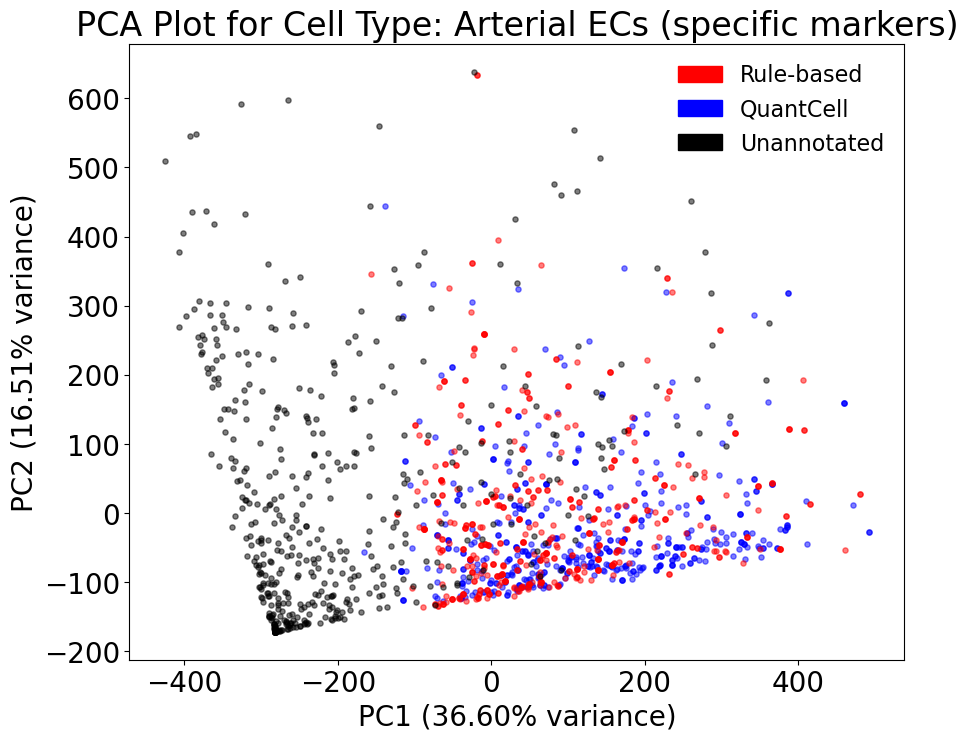

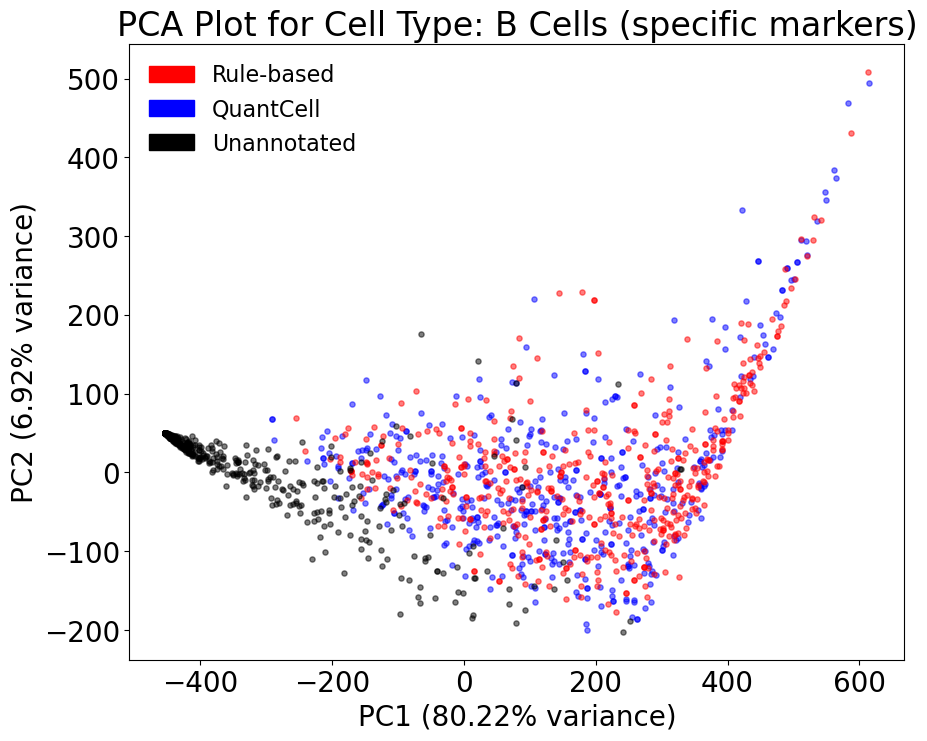

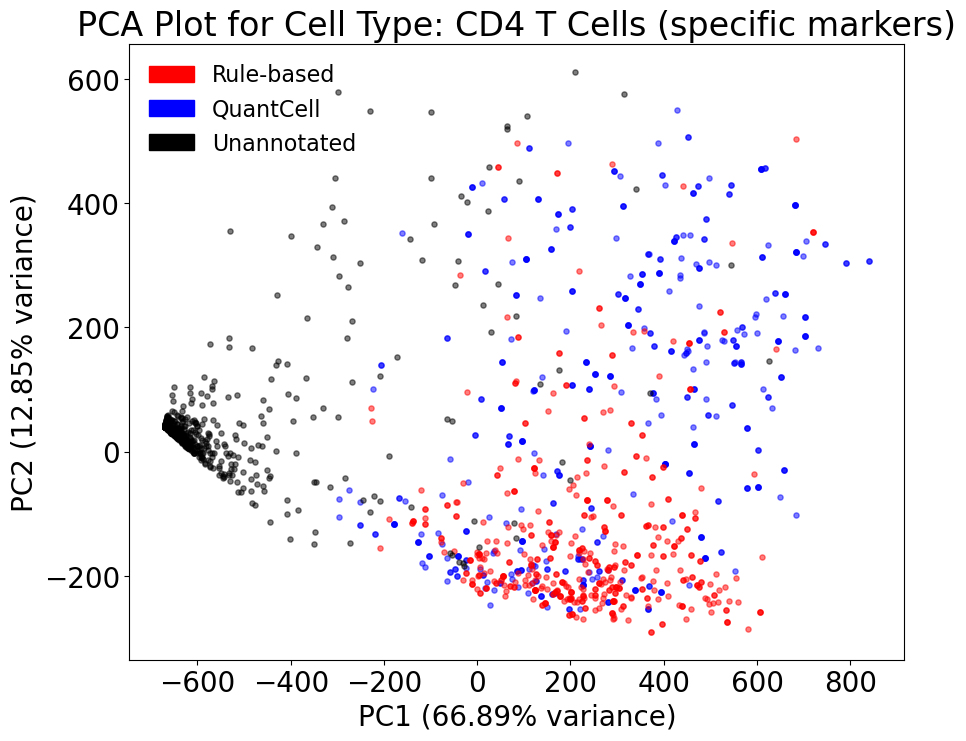

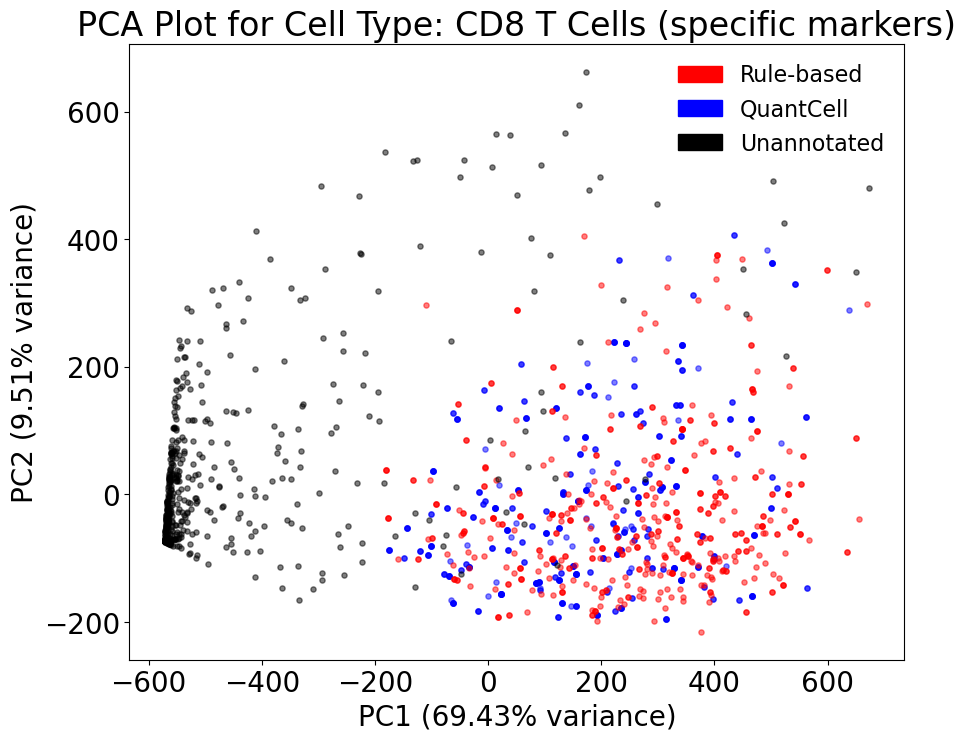

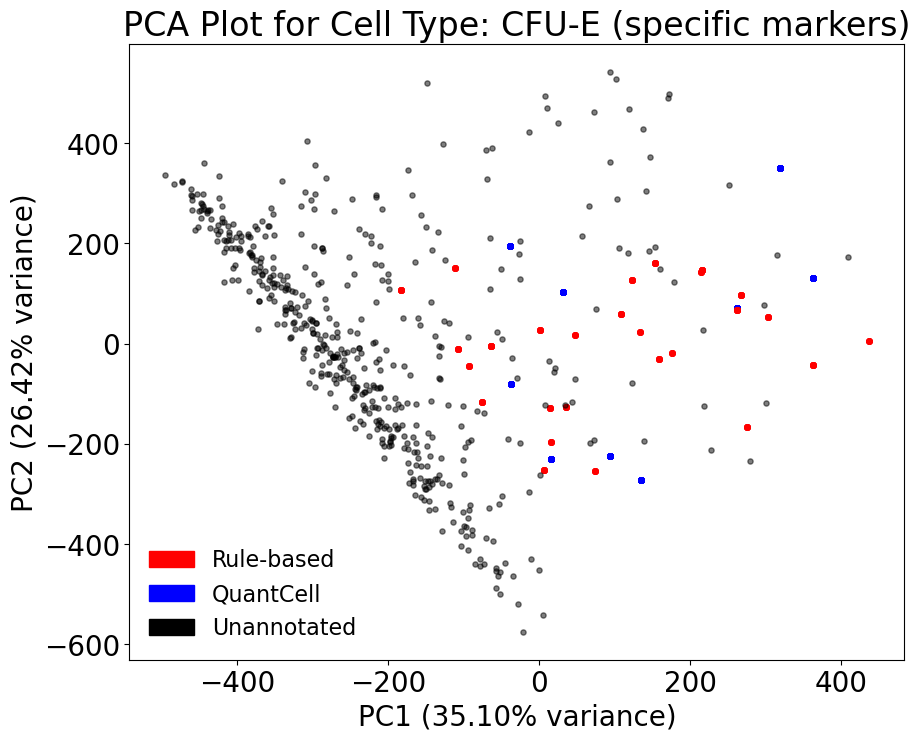

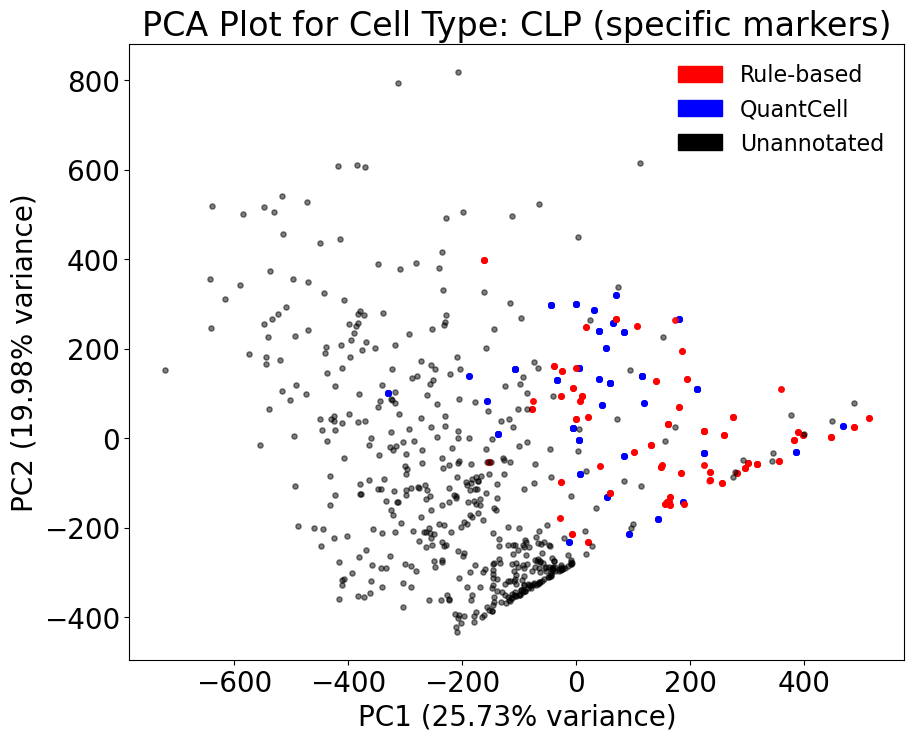

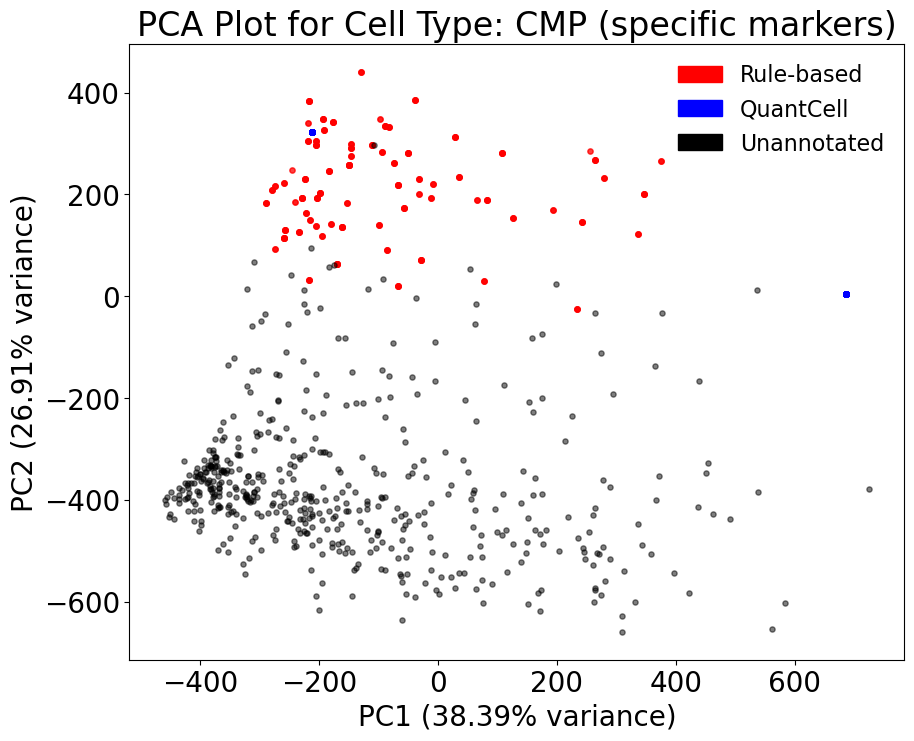

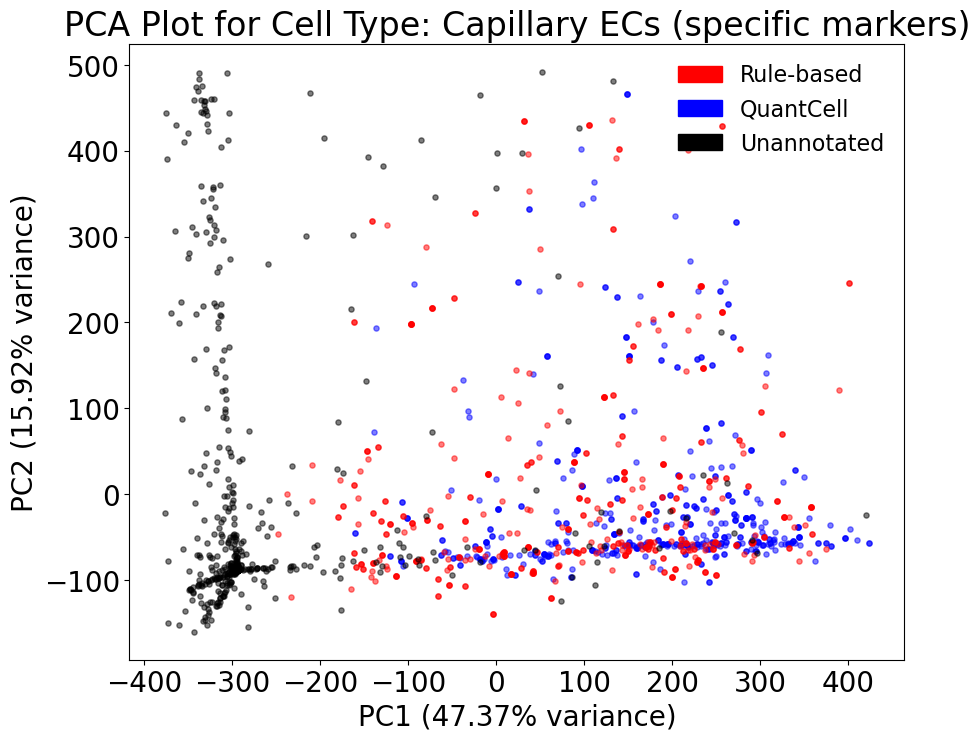

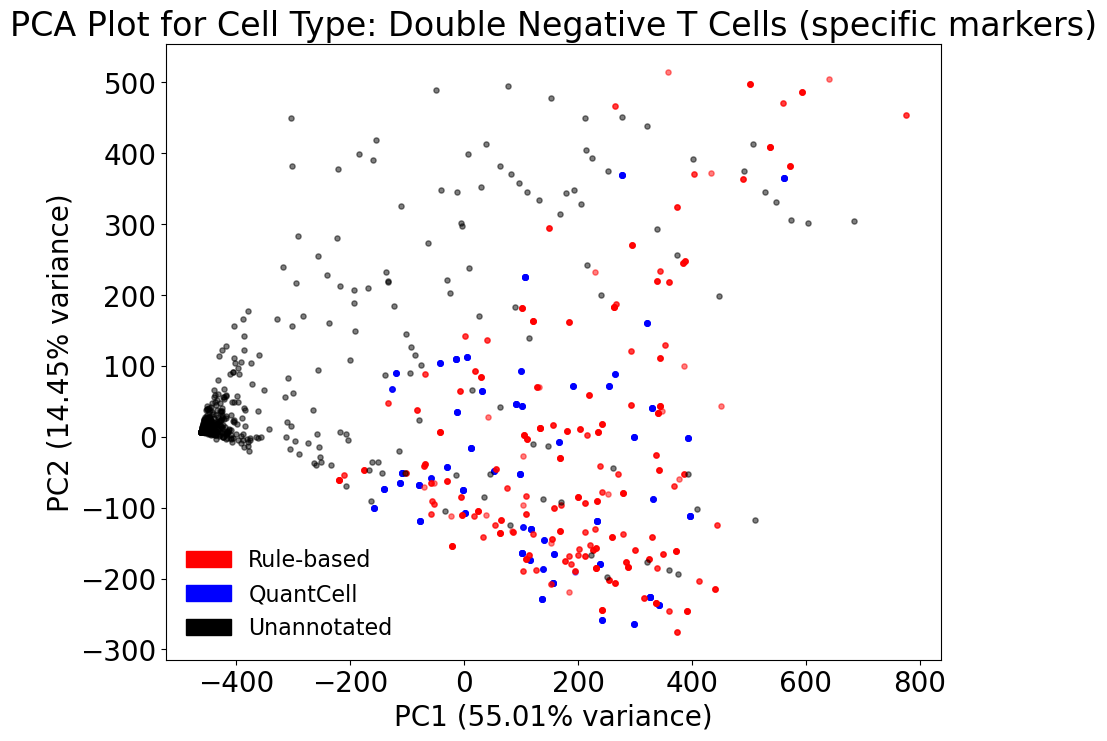

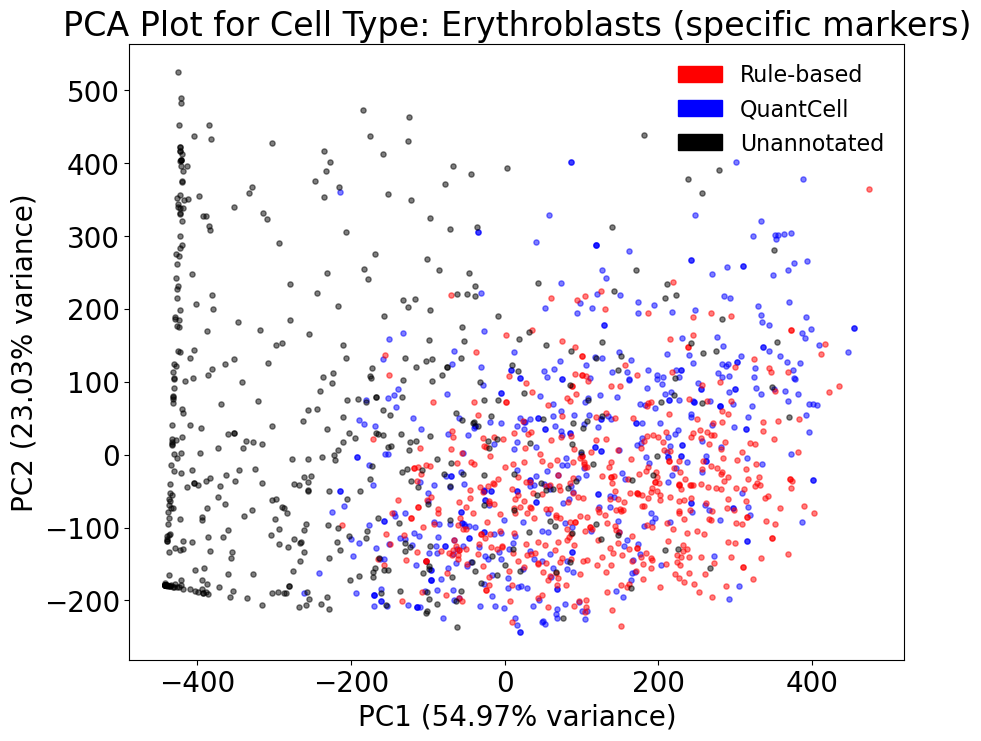

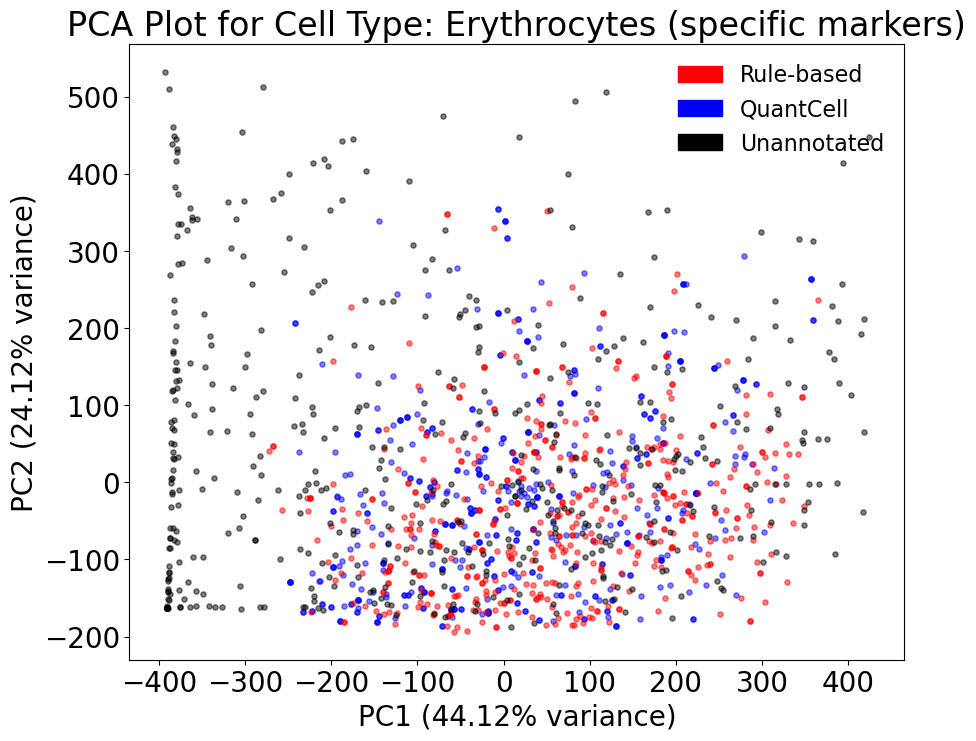

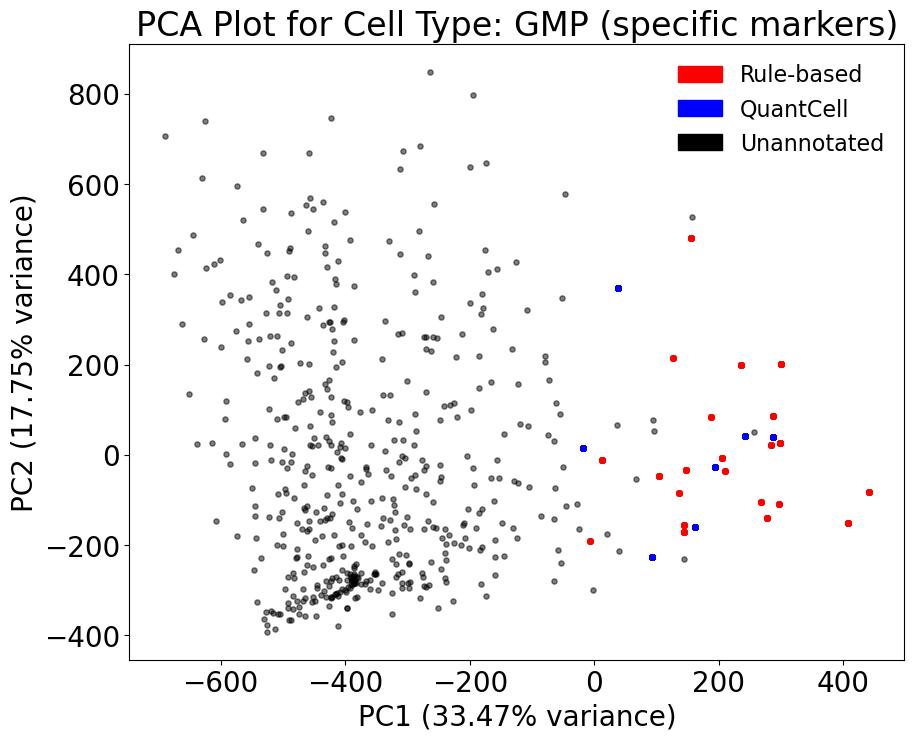

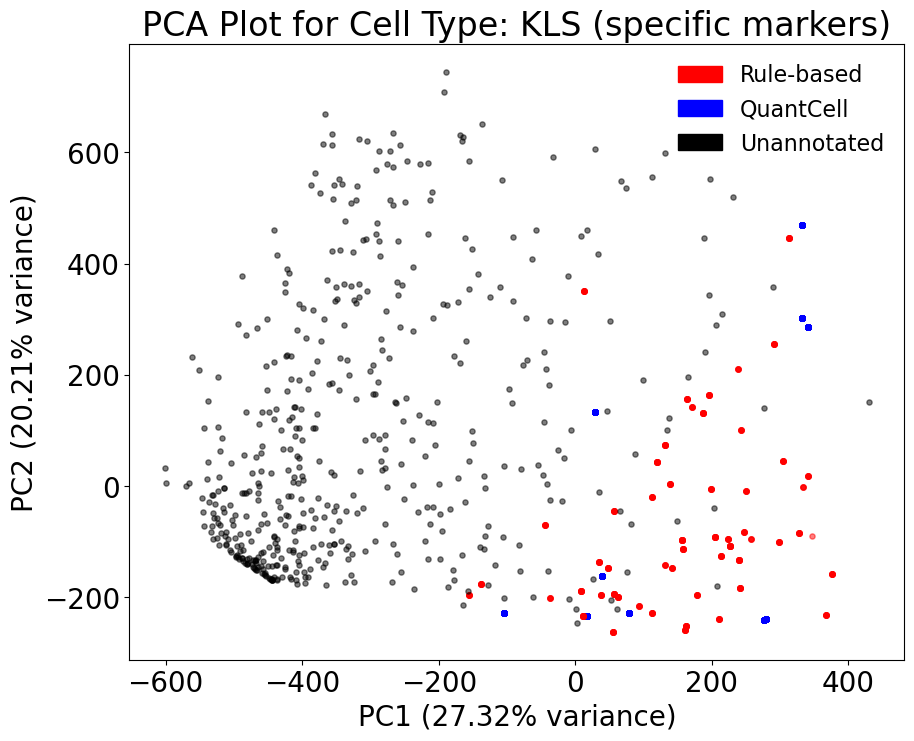

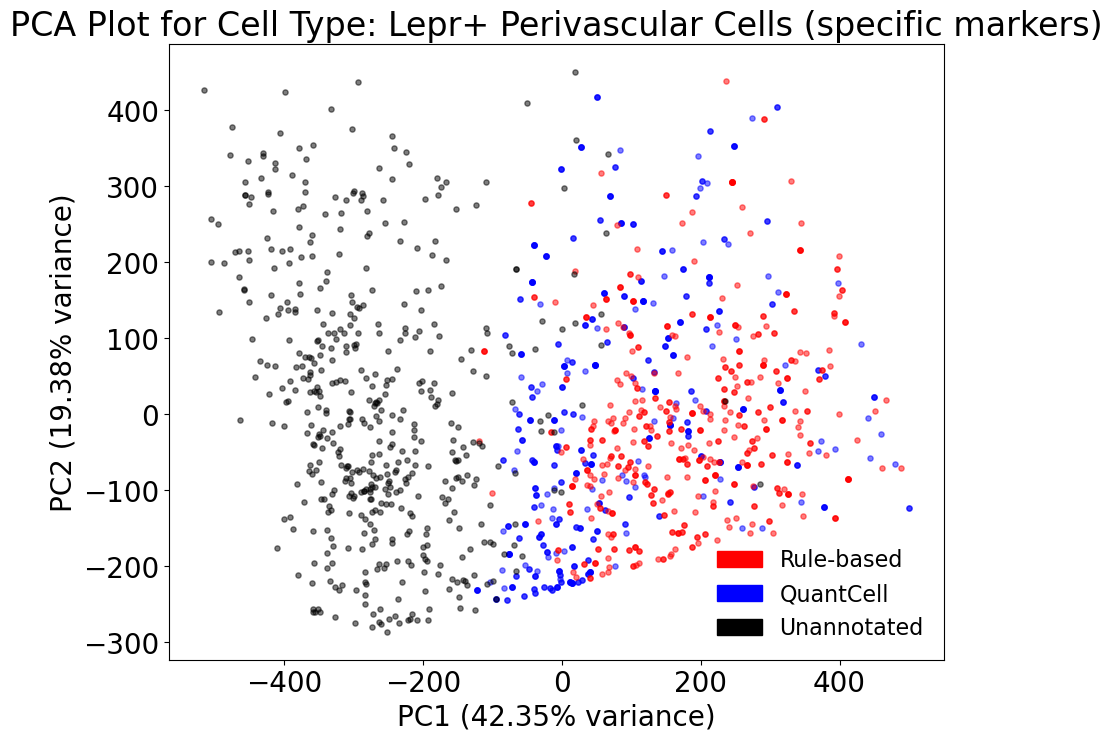

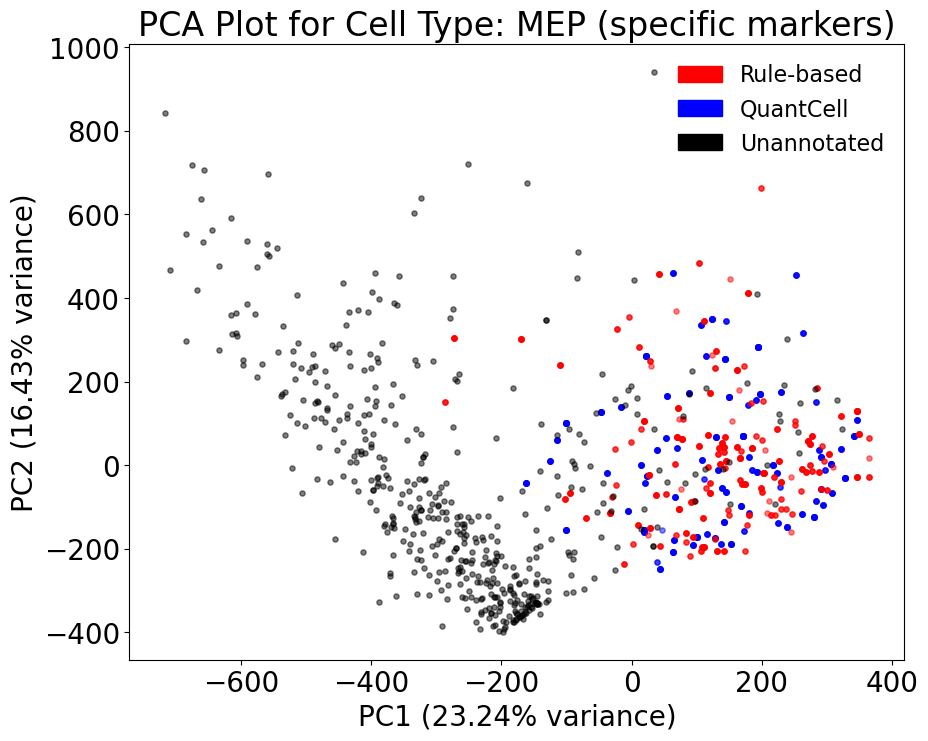

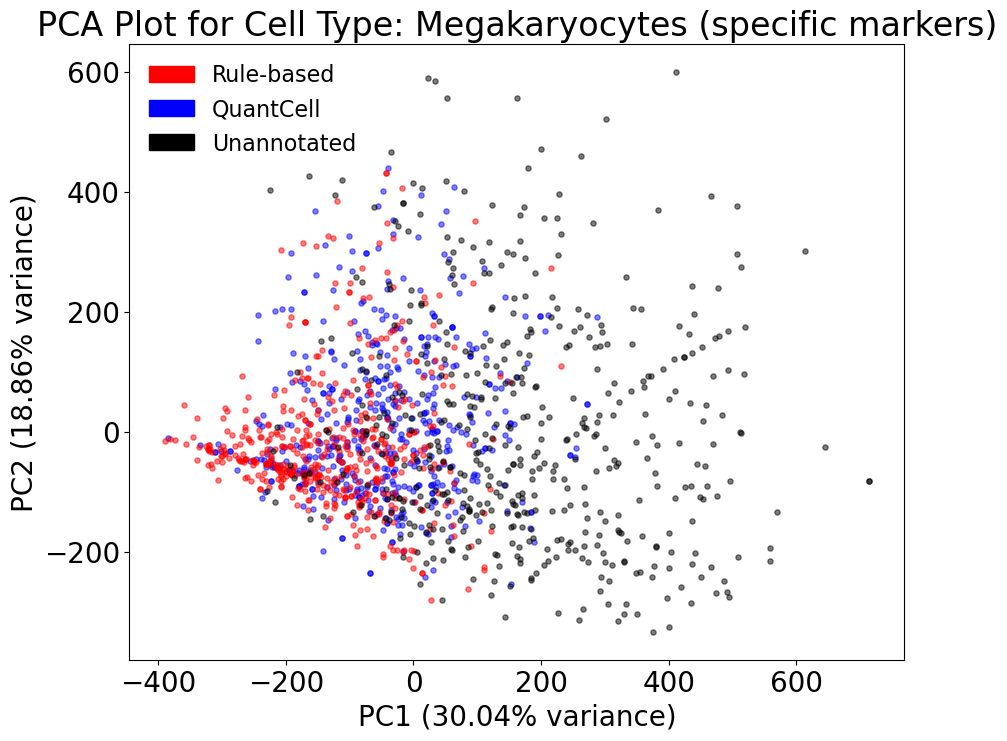

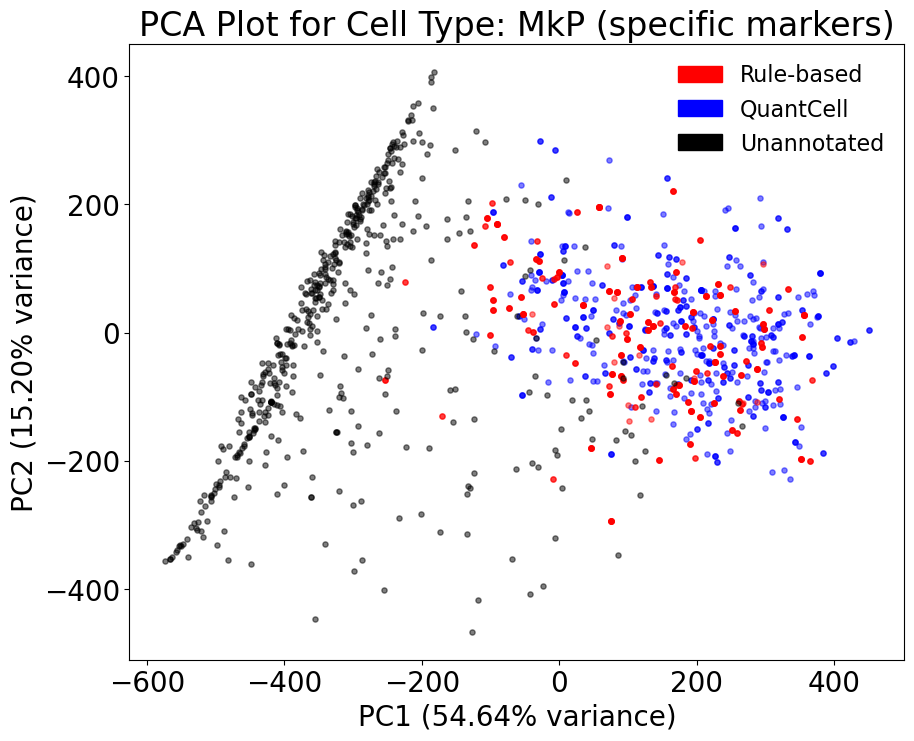

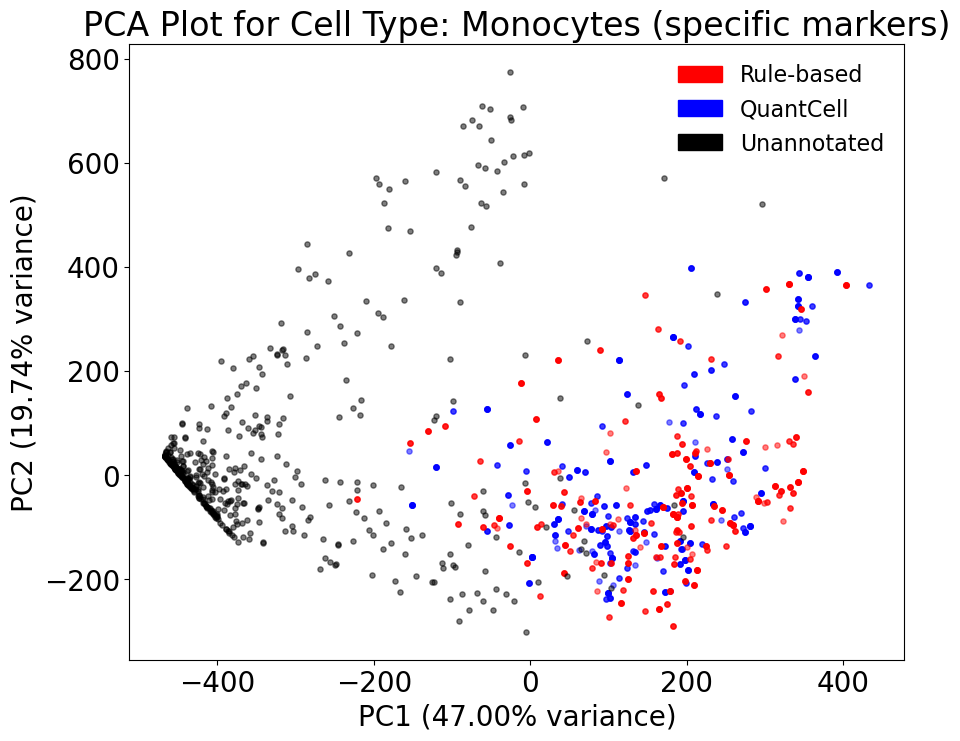

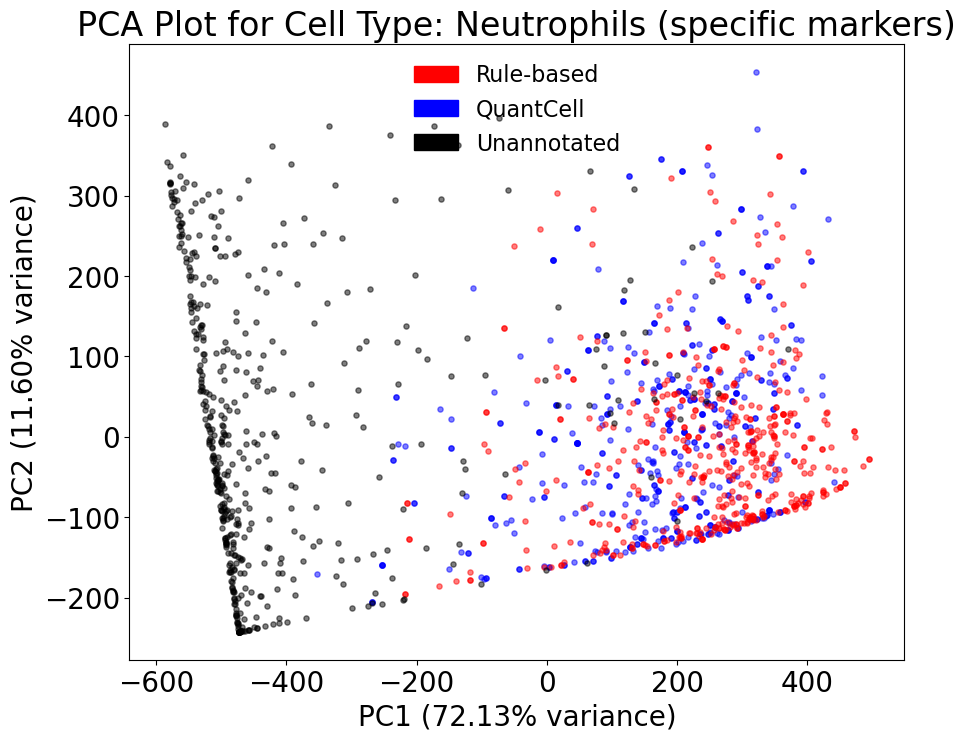

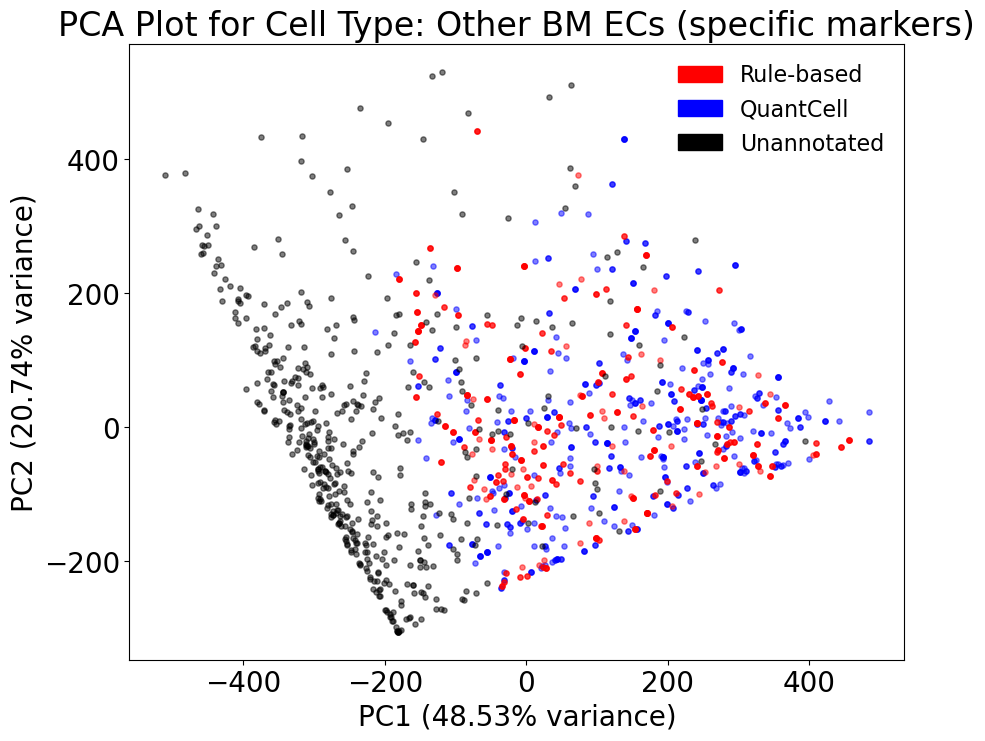

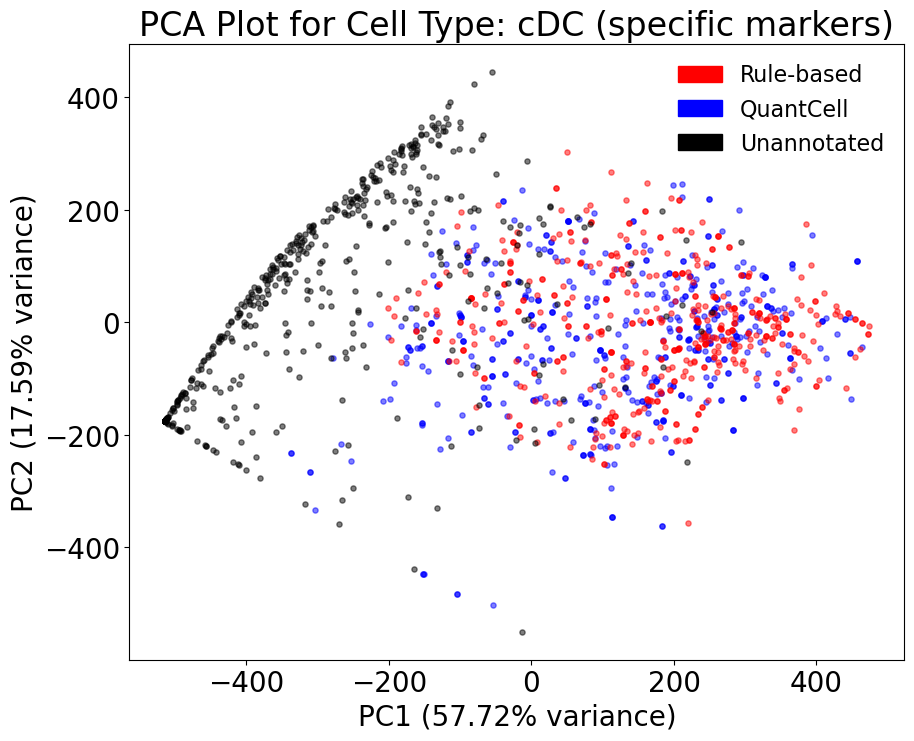

In [9]:
project.PCA_check(
    strategy='specific',
    num_sample=500,
    cell_types=None,
    output_dir=None,
    save=False
)

Save the annotated cells to a .csv file in the output folder

In [10]:
project.overwrite_codex()
project.save_codex()